# Clustering no supervisado — paso a paso

> **Para quién:** estudiantes que ya saben entrenar un clasificador o
> un regresor y van a enfrentarse por primera vez al clustering en el
> cuaderno 10 del proyecto 00.
>
> **Qué vas a aprender:**
> 1. Qué cambia cuando no tenemos etiquetas (`y`).
> 2. Cómo funciona **K-Means** por dentro.
> 3. Cómo elegir el número de clusters (`k`).
> 4. Cómo funciona **DBSCAN** y en qué se diferencia.
> 5. Cuándo elegir cada uno.
>
> **Prerrequisito:** haber visto al menos un modelo supervisado.


## 0. Supervisado vs no supervisado

En **supervisado** cada fila trae su respuesta correcta: `(X, y)`. El
modelo aprende la función `f(X) = y`. Ejemplo: predecir si un pasajero
del Titanic sobrevive.

En **no supervisado** solo tenemos `X`. Nadie nos dice cuál es la
respuesta correcta — buscamos **estructura** oculta: grupos naturales,
anomalías, dimensiones latentes.

El mismo conjunto de puntos, visto desde los dos lados:


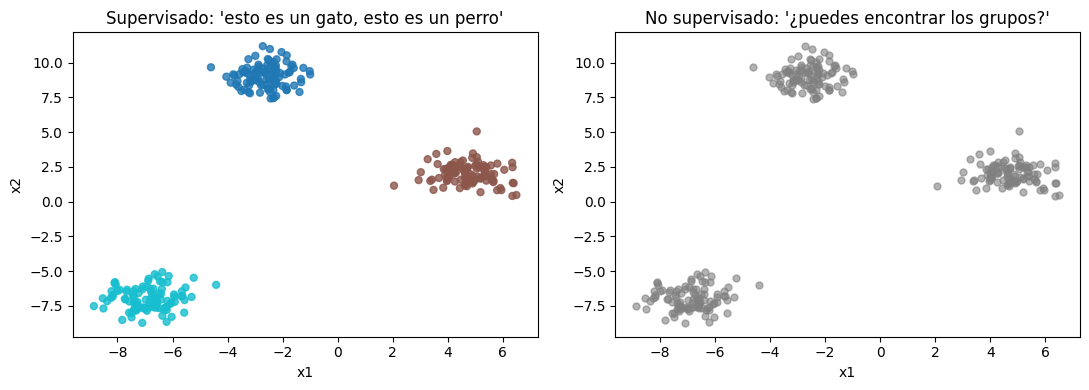

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Datos: 3 nubes gaussianas en 2D con sus etiquetas verdaderas
X, y_true = make_blobs(n_samples=300, centers=3, cluster_std=0.8,
                       random_state=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Supervisado: conocemos la etiqueta
ax1.scatter(X[:, 0], X[:, 1], c=y_true, cmap="tab10", s=25, alpha=0.8)
ax1.set_title("Supervisado: 'esto es un gato, esto es un perro'")
ax1.set_xlabel("x1"); ax1.set_ylabel("x2")

# No supervisado: solo tenemos los puntos
ax2.scatter(X[:, 0], X[:, 1], c="gray", s=25, alpha=0.6)
ax2.set_title("No supervisado: '¿puedes encontrar los grupos?'")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2")

fig.tight_layout()
plt.show()

A simple vista aquí hay tres grupos. Pero fíjate en el detalle: en el
mundo real nadie confirma que fueron tres. **El algoritmo tiene que
proponer una estructura y nosotros juzgamos si tiene sentido.** Esa es
la gran diferencia con lo supervisado — y por qué hay métricas raras
(silhouette, inertia) en vez de accuracy.

## 1. K-Means — la idea intuitiva

**Metáfora de las pizzerías:** eres el gerente de una cadena y vas a
abrir `k = 3` locales en una ciudad. ¿Dónde los pones para que la
distancia promedio del cliente al local sea mínima?

K-Means hace exactamente eso: coloca `k` **centroides** y asigna cada
punto al más cercano, minimizando la suma de distancias al cuadrado.

### El algoritmo paso a paso

1. **Inicializa**: elegir `k` puntos aleatorios como centroides.
2. **Asignar**: cada punto va al centroide más cercano.
3. **Mover**: cada centroide se mueve al promedio de sus puntos.
4. **Repetir** 2–3 hasta que los centroides dejen de moverse.

Vamos a verlo iterar.

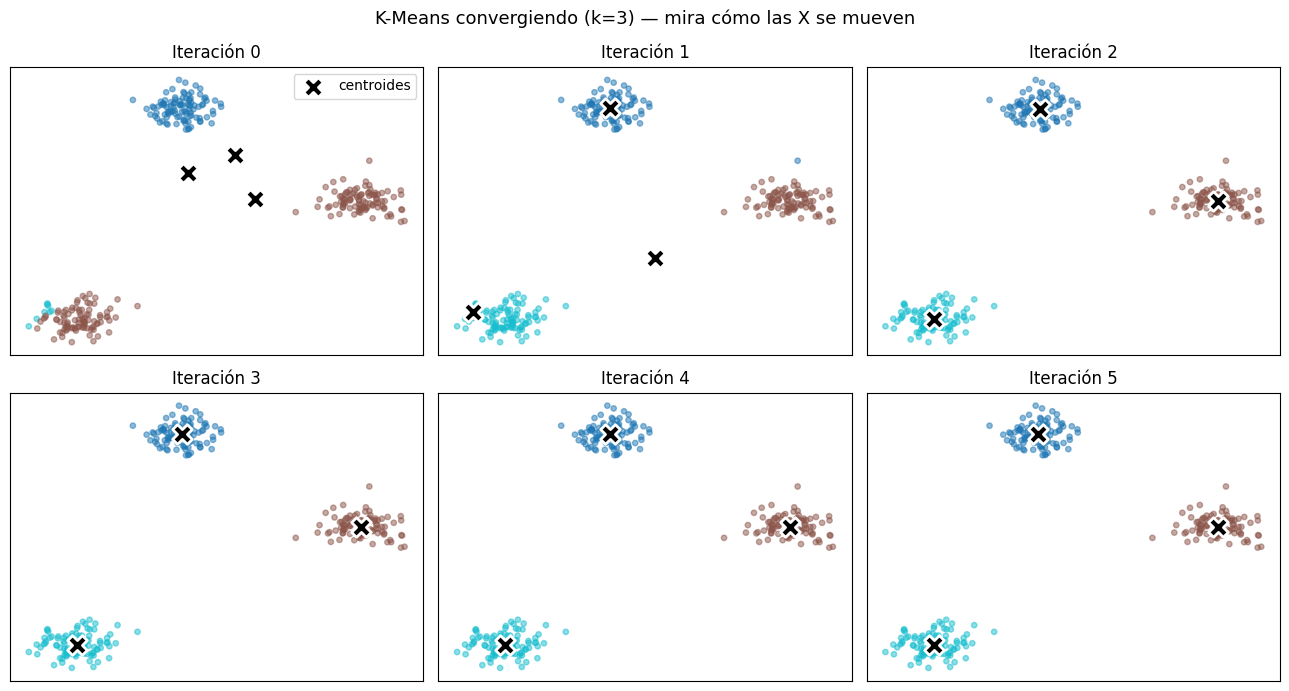

In [2]:
# Mismos datos. Vamos a hacer k-means "a mano" guardando el estado
# en cada iteracion para poder graficarlo.
rng = np.random.RandomState(0)
k = 3
# Centroides iniciales en posiciones arbitrarias (lejos del optimo adrede)
centroids = rng.uniform(low=X.min(axis=0), high=X.max(axis=0), size=(k, 2))

historia = []  # lista de (centroids, labels) por iteracion
for _ in range(6):
    # Paso 2: asignar cada punto al centroide mas cercano
    dists = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
    labels = dists.argmin(axis=1)
    historia.append((centroids.copy(), labels.copy()))
    # Paso 3: mover cada centroide al promedio de sus puntos
    for j in range(k):
        if (labels == j).any():
            centroids[j] = X[labels == j].mean(axis=0)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, (c, lbl) in enumerate(historia):
    ax = axes[i // 3, i % 3]
    ax.scatter(X[:, 0], X[:, 1], c=lbl, cmap="tab10", s=15, alpha=0.5)
    ax.scatter(c[:, 0], c[:, 1], c="black", marker="X", s=200,
               edgecolor="white", linewidth=2, label="centroides")
    ax.set_title(f"Iteración {i}")
    ax.set_xticks([]); ax.set_yticks([])
    if i == 0:
        ax.legend(loc="upper right")

fig.suptitle("K-Means convergiendo (k=3) — mira cómo las X se mueven",
             fontsize=13)
fig.tight_layout()
plt.show()

Observa cómo las **X negras** (los centroides) parten de posiciones
arbitrarias y en pocas iteraciones se asientan en el "centro" de cada
grupo. Los colores (asignaciones) se estabilizan junto con ellos.

En la práctica usamos `sklearn.cluster.KMeans`, que hace esto por
nosotros, con mejores inicializaciones (k-means++) y múltiples
reinicios para no quedar atrapados en un mínimo local.

## 2. ¿Cómo elegir `k`?

El algoritmo pide `k` como parámetro. Pero en la vida real **no
sabemos cuántos grupos hay** — ese es, en el fondo, el problema que
queremos resolver.

Veamos qué pasa con los mismos datos cuando le decimos `k = 2`,
`k = 4` o `k = 8`:

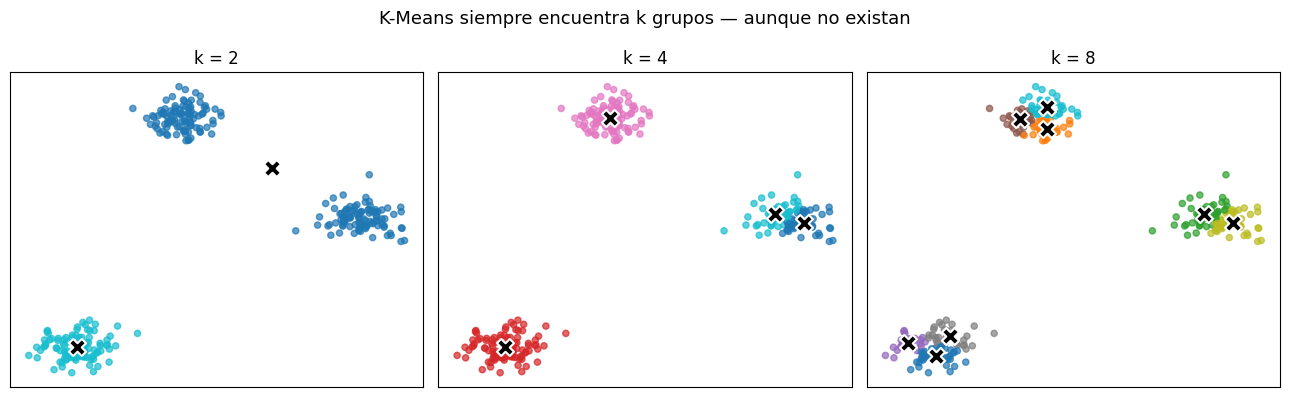

In [3]:
from sklearn.cluster import KMeans

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, k_try in zip(axes, [2, 4, 8]):
    km = KMeans(n_clusters=k_try, random_state=42, n_init=10).fit(X)
    ax.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="tab10",
               s=20, alpha=0.7)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               c="black", marker="X", s=150, edgecolor="white", linewidth=1.5)
    ax.set_title(f"k = {k_try}")
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("K-Means siempre encuentra k grupos — aunque no existan",
             fontsize=13)
fig.tight_layout()
plt.show()

Lección clave: **K-Means siempre te devuelve `k` grupos, aunque los
datos solo tengan 3.** Con `k = 8` parte artificialmente los grupos
reales en pedazos. Elegir `k` es nuestra responsabilidad.

### Dos heurísticas: elbow + silhouette

- **Elbow (codo)**: para cada `k`, calculamos la **inertia** (suma de
  distancias al centroide). Siempre baja al aumentar `k`; buscamos
  el "codo" donde la caída se aplana.
- **Silhouette**: mide qué tan separado está cada punto del cluster
  vecino. Va de -1 a 1; más alto es mejor.

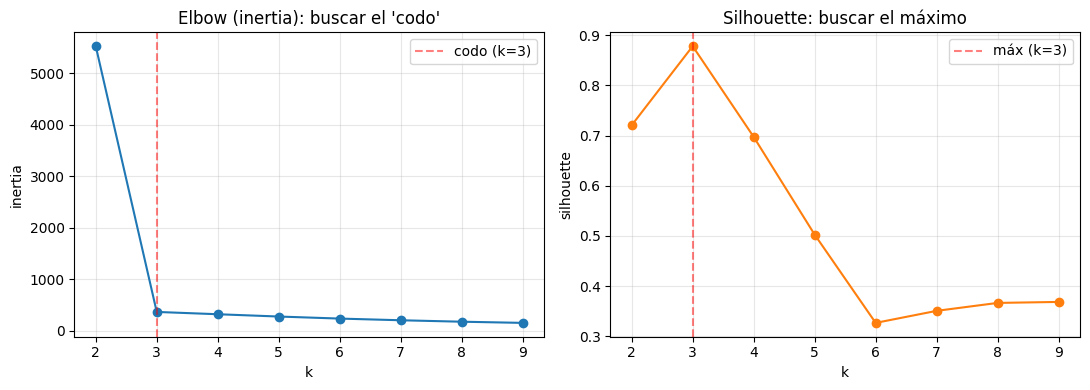

In [4]:
from sklearn.metrics import silhouette_score

ks = range(2, 10)
inertias = []
silhouettes = []
for k_try in ks:
    km = KMeans(n_clusters=k_try, random_state=42, n_init=10).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(list(ks), inertias, marker="o")
ax1.axvline(3, color="red", linestyle="--", alpha=0.5, label="codo (k=3)")
ax1.set_xlabel("k"); ax1.set_ylabel("inertia")
ax1.set_title("Elbow (inertia): buscar el 'codo'")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(list(ks), silhouettes, marker="o", color="C1")
ax2.axvline(3, color="red", linestyle="--", alpha=0.5, label="máx (k=3)")
ax2.set_xlabel("k"); ax2.set_ylabel("silhouette")
ax2.set_title("Silhouette: buscar el máximo")
ax2.legend(); ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

En este dataset tan limpio, ambas métricas coinciden en `k = 3`. En
datos reales suelen **discrepar** — el cuaderno 10 del proyecto 00 lo
muestra: silhouette elige k = 2, davies_bouldin elige k = 4. Allí la
decisión final es de negocio, no un `argmax()`.

## 3. DBSCAN — la idea de densidad

K-Means asume que los clusters son **nubes esféricas** alrededor de un
centro. Pero muchos datos reales no son así: pueden tener forma de
media luna, de anillo, o puede haber puntos aislados que no pertenecen
a ningún grupo.

**DBSCAN** cambia la pregunta. En vez de "¿cuál es el centro?", pregunta
"**¿dónde hay mucha gente cerca?**". Un cluster es una región de **alta
densidad** rodeada de regiones de **baja densidad**.

### La metáfora del mapa nocturno

Imagina un mapa nocturno de luces. Las zonas brillantes son barrios —
ahí hay muchas casas cerca. Las luces aisladas en medio del campo son
casas rurales — no forman barrio, son **ruido**. DBSCAN hace eso con
puntos: detecta zonas densas y descarta los aislados.

### Los dos parámetros

- **ε (`eps`)**: el radio del "vecindario". ¿Qué tan cerca es "cerca"?
- **`min_samples`**: cuántos vecinos (incluyendo el propio punto)
  necesita un punto para considerarse **núcleo** de un cluster.

### Tres tipos de punto

- **Núcleo**: tiene ≥ `min_samples` vecinos dentro del radio ε.
- **Frontera**: no es núcleo, pero cae dentro del vecindario de uno.
- **Ruido**: ni núcleo ni frontera. Etiqueta `-1`.

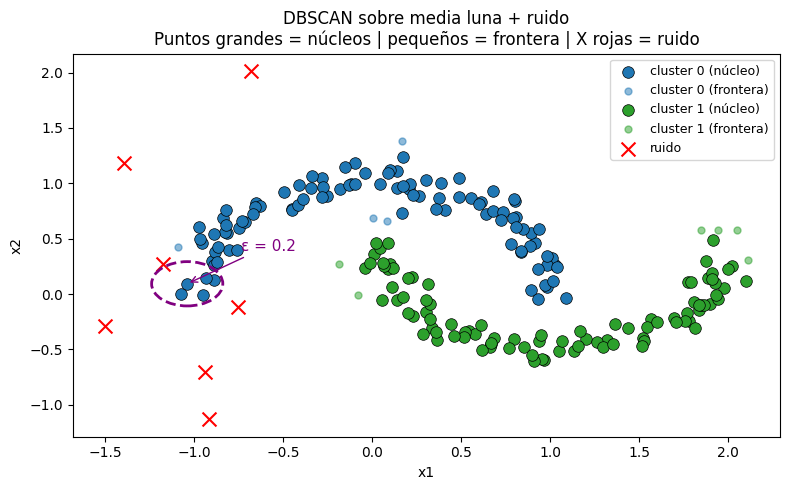

Clusters encontrados: 2
Puntos de ruido: 7 de 210


In [5]:
from sklearn.cluster import DBSCAN
from matplotlib.patches import Circle

# Dataset en forma de media luna + algunos puntos de ruido
from sklearn.datasets import make_moons
X_m, _ = make_moons(n_samples=200, noise=0.08, random_state=42)
# Añadimos 10 puntos de ruido disperso
ruido = np.random.RandomState(1).uniform(low=-1.5, high=2.5, size=(10, 2))
X_m = np.vstack([X_m, ruido])

db = DBSCAN(eps=0.2, min_samples=5).fit(X_m)
labels = db.labels_
# Identificar nucleos vs no-nucleos
nucleos = np.zeros_like(labels, dtype=bool)
nucleos[db.core_sample_indices_] = True

fig, ax = plt.subplots(figsize=(8, 5))
colores = {-1: "red", 0: "C0", 1: "C2"}
etiquetas_leyenda = {-1: "ruido", 0: "cluster 0", 1: "cluster 1"}

for lab in np.unique(labels):
    mask = labels == lab
    nucleo_mask = mask & nucleos
    frontera_mask = mask & ~nucleos
    ax.scatter(X_m[nucleo_mask, 0], X_m[nucleo_mask, 1],
               c=colores[lab], s=70, edgecolor="black", linewidth=0.5,
               label=f"{etiquetas_leyenda[lab]} (núcleo)" if lab != -1 else None)
    if frontera_mask.any() and lab != -1:
        ax.scatter(X_m[frontera_mask, 0], X_m[frontera_mask, 1],
                   c=colores[lab], s=25, alpha=0.5,
                   label=f"{etiquetas_leyenda[lab]} (frontera)")

# Puntos de ruido con X
ruido_mask = labels == -1
ax.scatter(X_m[ruido_mask, 0], X_m[ruido_mask, 1],
           c="red", marker="x", s=100, label="ruido")

# Dibujar el radio eps alrededor de un nucleo cualquiera, para ver que mide
nucleo_ejemplo = X_m[db.core_sample_indices_[0]]
ax.add_patch(Circle(nucleo_ejemplo, radius=0.2, fill=False,
                     linestyle="--", color="purple", linewidth=2))
ax.annotate("ε = 0.2", xy=nucleo_ejemplo, xytext=(nucleo_ejemplo[0] + 0.3, nucleo_ejemplo[1] + 0.3),
            fontsize=11, color="purple",
            arrowprops=dict(arrowstyle="->", color="purple"))

ax.set_title("DBSCAN sobre media luna + ruido\n"
             "Puntos grandes = núcleos | pequeños = frontera | X rojas = ruido")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout()
plt.show()

print(f"Clusters encontrados: {len(set(labels)) - (1 if -1 in labels else 0)}")
print(f"Puntos de ruido: {(labels == -1).sum()} de {len(labels)}")

Observa cómo DBSCAN detectó las **dos medias lunas** sin problemas —
algo que K-Means no puede hacer bien porque no son esféricas. Y los 10
puntos de ruido que añadimos quedaron correctamente marcados con `-1`
(las X rojas) en vez de obligarlos a pertenecer a algún cluster.

El círculo violeta muestra el vecindario ε = 0.2 alrededor de un
núcleo. **Si bajamos ε**, menos puntos serán núcleo y aparecerá más
ruido. **Si lo subimos**, los dos clusters se fusionarán en uno.

## 4. ¿K-Means o DBSCAN?

Depende de la forma de los datos y del problema. Comparemos los dos
sobre tres datasets distintos:

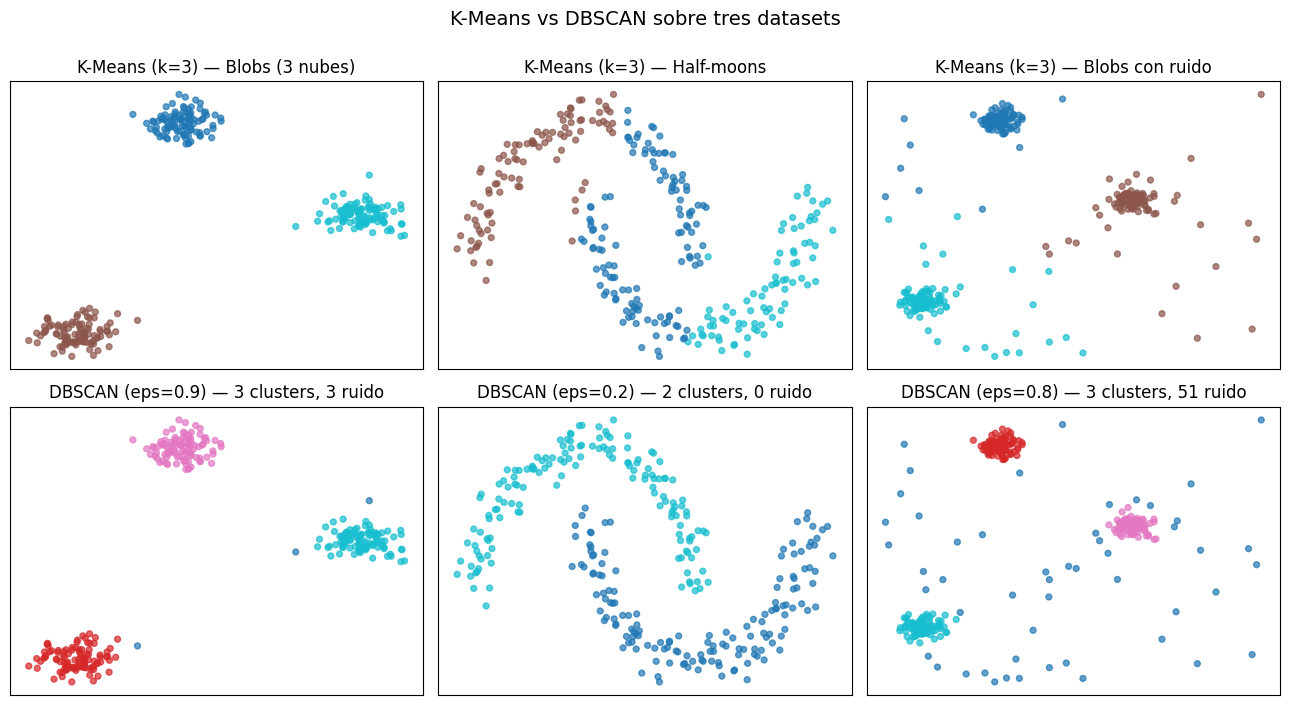

In [6]:
from sklearn.datasets import make_blobs, make_moons

datasets = {
    "Blobs (3 nubes)": make_blobs(n_samples=300, centers=3, cluster_std=0.8,
                                   random_state=42)[0],
    "Half-moons": make_moons(n_samples=300, noise=0.08, random_state=42)[0],
    "Blobs con ruido": np.vstack([
        make_blobs(n_samples=250, centers=3, cluster_std=0.6, random_state=42)[0],
        np.random.RandomState(2).uniform(low=-12, high=12, size=(50, 2)),
    ]),
}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for col, (nombre, Xd) in enumerate(datasets.items()):
    # K-Means
    km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xd)
    axes[0, col].scatter(Xd[:, 0], Xd[:, 1], c=km.labels_, cmap="tab10",
                          s=18, alpha=0.7)
    axes[0, col].set_title(f"K-Means (k=3) — {nombre}")
    axes[0, col].set_xticks([]); axes[0, col].set_yticks([])

    # DBSCAN con parametros razonables por dataset
    eps = {"Blobs (3 nubes)": 0.9, "Half-moons": 0.2, "Blobs con ruido": 0.8}
    db = DBSCAN(eps=eps[nombre], min_samples=5).fit(Xd)
    axes[1, col].scatter(Xd[:, 0], Xd[:, 1], c=db.labels_, cmap="tab10",
                          s=18, alpha=0.7)
    n_clust = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    n_ruido = (db.labels_ == -1).sum()
    axes[1, col].set_title(
        f"DBSCAN (eps={eps[nombre]}) — {n_clust} clusters, "
        f"{n_ruido} ruido"
    )
    axes[1, col].set_xticks([]); axes[1, col].set_yticks([])

fig.suptitle("K-Means vs DBSCAN sobre tres datasets", fontsize=14, y=1.00)
fig.tight_layout()
plt.show()

### Lectura

| Dataset | K-Means | DBSCAN |
|---|---|---|
| **Blobs** (3 nubes esféricas) | Perfecto | También funciona |
| **Half-moons** (formas curvas) | Falla: parte los medios lunas | Perfecto |
| **Blobs con ruido** (3 nubes + 50 puntos aleatorios) | Fuerza al ruido a entrar en algún cluster | Detecta las 3 nubes **y** marca ruido |

### Resumen cuándo usar cada uno

**K-Means** cuando:
- Las etnias/segmentos son razonablemente esféricos.
- Necesitas una asignación forzosa (cada cliente a algún segmento).
- Quieres algo rápido, interpretable, con centroides claros.
- Ejemplo típico: **segmentación RFM de clientes**, documentos por tema.

**DBSCAN** cuando:
- Los grupos tienen forma arbitraria.
- Hay ruido o outliers que no quieres asignar a la fuerza.
- No sabes cuántos clusters hay (DBSCAN los descubre).
- Ejemplo típico: **detección de anomalías**, geo-datos, análisis de red.

## 5. Puente al proyecto 00

En el cuaderno `10_segmentacion_no_supervisada.ipynb` vas a aplicar
exactamente esto, pero sobre ~5 000 clientes reales de un retail
online (variables RFM: recencia, frecuencia, monetario).

**Lo que ya sabes antes de abrirlo:**

- Vas a ver una tabla de métricas (inertia, silhouette, davies_bouldin)
  para k = 2 … 7. **Van a discrepar.** Esa tabla reemplaza al gráfico
  elbow + silhouette de la sección 2.
- La decisión final de `k` es de **negocio**, no un `argmax()`. En el
  cuaderno 10 se eligen `k = 4` porque da perfiles de marketing
  accionables (campeones, leales, en riesgo, perdidos), aunque
  silhouette prefiere k = 2.
- Vas a ver un **scatter PCA 2D de los clusters**. Igual que la Sección
  0 de este cuaderno, pero sobre datos reales de 8 dimensiones.
- DBSCAN va a marcar ~46% de los clientes como **ruido**. No es un
  bug: significa que la densidad **no** es un buen separador en
  clientes RFM (todos viven en una nube única). DBSCAN se queda como
  **detector de outliers**, no como segmentador.

**Preguntas para asegurarte de que entendiste:**

1. ¿Qué pasaría si en el cuaderno 10 eligiéramos k = 8 en vez de k = 4?
2. ¿Por qué DBSCAN "falla" en clientes RFM pero funciona en los
   half-moons de este cuaderno?
3. Si marketing te dice "preferimos 3 segmentos para ser más
   accionables", ¿cómo le explicas que la métrica dice otra cosa?

Ahora sí, abre:

```
projects/00-segmentacion-clientes/notebooks/10_segmentacion_no_supervisada.ipynb
```
